<a href="https://colab.research.google.com/github/shruthilayak11/ShelfLife-Saver-Predictive-Discounting-Engine/blob/main/ShelfLife_Saver_Predictive_Discounting_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Optimal Pricing of Near-Expiry Products

**Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


**Load Dataset**

In [ ]:
df = pd.read_csv('/content/near_expiry_products.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (3000, 11)


,Product_ID,Product_Category,Original_Price,Discount_Percentage,Days_Until_Expiry,Historical_Average_Demand,Previous_Week_Sales,Day_of_Week,Season,Stock_Available,Units_Sold
0,PRD0001,Meat,181,60,0,13.2,82,Friday,Monsoon,61,25
1,PRD0002,Dairy,135,40,4,25.2,225,Saturday,Winter,68,68
2,PRD0003,Fruits,205,0,4,42.5,225,Thursday,Monsoon,152,19
3,PRD0004,Meat,453,20,1,26.8,163,Saturday,Summer,90,56
4,PRD0005,Fruits,176,0,5,36.5,273,Saturday,Spring,108,55


**Data Understanding and Cleaning**

In [ ]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_ID                 3000 non-null   object 
 1   Product_Category           3000 non-null   object 
 2   Original_Price             3000 non-null   int64  
 3   Discount_Percentage        3000 non-null   int64  
 4   Days_Until_Expiry          3000 non-null   int64  
 5   Historical_Average_Demand  3000 non-null   float64
 6   Previous_Week_Sales        3000 non-null   int64  
 7   Day_of_Week                3000 non-null   object 
 8   Season                     3000 non-null   object 
 9   Stock_Available            3000 non-null   int64  
 10  Units_Sold                 3000 non-null   int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 257.9+ KB


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Product_ID                   0
Product_Category             0
Original_Price               0
Discount_Percentage          0
Days_Until_Expiry            0
Historical_Average_Demand    0
Previous_Week_Sales          0
Day_of_Week                  0
Season                       0
Stock_Available              0
Units_Sold                   0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

print("Numerical data summary:")
df.describe()

Number of duplicate rows: 0
Numerical data summary:


,Original_Price,Discount_Percentage,Days_Until_Expiry,Historical_Average_Demand,Previous_Week_Sales,Stock_Available,Units_Sold
count,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,119.61000,23.583333,5.653000,40.929067,293.595333,168.037333,72.701667
std,133.14047,19.089644,7.326697,28.941124,233.112138,155.756406,68.344863
min,10.00000,0.000000,0.000000,1.500000,11.000000,8.000000,1.000000
25%,43.00000,5.000000,1.000000,20.900000,140.000000,70.000000,28.000000
50%,72.00000,20.000000,3.000000,33.800000,233.000000,121.000000,53.000000
75%,138.00000,35.000000,6.000000,53.100000,373.250000,213.000000,93.000000
max,900.00000,80.000000,45.000000,321.300000,2885.000000,1700.000000,848.000000


In [ ]:
print("Minimum values:")
print(df.select_dtypes(include=np.number).min())

print("\nMaximum values:")
print(df.select_dtypes(include=np.number).max())

Minimum values:
Original_Price               10.0
Discount_Percentage           0.0
Days_Until_Expiry             0.0
Historical_Average_Demand     1.5
Previous_Week_Sales          11.0
Stock_Available               8.0
Units_Sold                    1.0
dtype: float64

Maximum values:
Original_Price                900.0
Discount_Percentage            80.0
Days_Until_Expiry              45.0
Historical_Average_Demand     321.3
Previous_Week_Sales          2885.0
Stock_Available              1700.0
Units_Sold                    848.0
dtype: float64


**Data Preprocessing**

In [ ]:
df = df.drop('Product_ID', axis=1)

print("Product_ID removed.")
print("New shape:", df.shape)

df = pd.get_dummies(
    df,
    columns=['Product_Category', 'Day_of_Week', 'Season'],
    drop_first=True
)

print("Categorical columns encoded.")
print("New shape:", df.shape)

X = df.drop('Units_Sold', axis=1)
y = df['Units_Sold']

print("Features (X):", X.shape)
print("Target (y):", y.shape)


Product_ID removed.
New shape: (3000, 10)
Categorical columns encoded.
New shape: (3000, 21)
Features (X): (3000, 20)
Target (y): (3000,)


**Train-Test Split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2400, 20)
Testing data: (600, 20)


**Multiple Linear Regression**

In [ ]:
# Create and train Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict on test data
linear_pred = linear_model.predict(X_test)

# Evaluate the model
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("Multiple Linear Regression Results")
print("MAE :", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R²  :", round(linear_r2, 2))

Multiple Linear Regression Results
MAE : 24.75
RMSE: 39.82
R²  : 0.69


**Polynomial Regression**

In [ ]:
# Create polynomial features
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Train Polynomial Regression
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# Predict
poly_pred = poly_model.predict(X_test_poly)

# Evaluate
poly_mae = mean_absolute_error(y_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
poly_r2 = r2_score(y_test, poly_pred)

print("Polynomial Regression Results")
print("MAE :", round(poly_mae, 2))
print("RMSE:", round(poly_rmse, 2))
print("R²  :", round(poly_r2, 2))

Polynomial Regression Results
MAE : 21.61
RMSE: 32.44
R²  : 0.79


**Random Forest Regression**

In [ ]:
# Create and train Random Forest Regression model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Regression Results")
print("MAE :", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²  :", round(rf_r2, 2))

Random Forest Regression Results
MAE : 21.04
RMSE: 35.21
R²  : 0.76


**Model Comparison**

In [ ]:
comparison = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Polynomial Regression',
        'Random Forest Regression'
    ],
    'MAE': [
        linear_mae,
        poly_mae,
        rf_mae
    ],
    'RMSE': [
        linear_rmse,
        poly_rmse,
        rf_rmse
    ],
    'R2': [
        linear_r2,
        poly_r2,
        rf_r2
    ]
})

comparison.round(2)

,Model,MAE,RMSE,R2
0,Multiple Linear Regression,24.75,39.82,0.69
1,Polynomial Regression,21.61,32.44,0.79
2,Random Forest Regression,21.04,35.21,0.76


**Best Model Selection**

In [ ]:
best_model_name = 'Polynomial Regression'
best_model = poly_model

print("Best Model:", best_model_name)
print("R² Score:", round(poly_r2, 2))
print("RMSE:", round(poly_rmse, 2))

Best Model: Polynomial Regression
R² Score: 0.79
RMSE: 32.44


**Discount Simulation**

In [ ]:
# Example near-expiry product
product = {
    'Original_Price': 60,
    'Days_Until_Expiry': 2,
    'Historical_Average_Demand': 35,
    'Previous_Week_Sales': 40,
    'Stock_Available': 50,
    'Product_Category': 'Dairy',
    'Day_of_Week': 'Saturday',
    'Season': 'Summer'
}

# Discount levels to test
discounts = [0, 5, 10, 15, 20, 25, 30]

simulation = []

for discount in discounts:

    # Create input row
    input_data = pd.DataFrame([{
        'Original_Price': product['Original_Price'],
        'Discount_Percentage': discount,
        'Days_Until_Expiry': product['Days_Until_Expiry'],
        'Historical_Average_Demand': product['Historical_Average_Demand'],
        'Previous_Week_Sales': product['Previous_Week_Sales'],
        'Stock_Available': product['Stock_Available'],
        'Product_Category': product['Product_Category'],
        'Day_of_Week': product['Day_of_Week'],
        'Season': product['Season']
    }])

    # Apply same encoding as training data
    input_data = pd.get_dummies(
        input_data,
        columns=['Product_Category', 'Day_of_Week', 'Season'],
        drop_first=True
    )

    # Make sure input has exactly the same columns as X
    input_data = input_data.reindex(columns=X.columns, fill_value=0)

    # Polynomial transformation
    input_poly = poly.transform(input_data)

    # Predict demand
    predicted_demand = poly_model.predict(input_poly)[0]

    # Demand cannot exceed available stock
    predicted_sales = min(predicted_demand, product['Stock_Available'])

    # Calculate discounted selling price
    selling_price = product['Original_Price'] * (1 - discount / 100)

    # Expected revenue
    revenue = predicted_sales * selling_price

    # Estimated unsold stock
    unsold = max(product['Stock_Available'] - predicted_sales, 0)

    simulation.append([
        discount,
        predicted_sales,
        selling_price,
        revenue,
        unsold
    ])

simulation_df = pd.DataFrame(
    simulation,
    columns=[
        'Discount_Percentage',
        'Predicted_Sales',
        'Selling_Price',
        'Expected_Revenue',
        'Estimated_Unsold'
    ]
)

simulation_df.round(2)

,Discount_Percentage,Predicted_Sales,Selling_Price,Expected_Revenue,Estimated_Unsold
0,0,5.42,60.0,325.05,44.58
1,5,14.32,57.0,816.44,35.68
2,10,22.17,54.0,1196.93,27.83
3,15,28.94,51.0,1476.09,21.06
4,20,34.66,48.0,1663.51,15.34
5,25,39.31,45.0,1768.76,10.69
6,30,42.89,42.0,1801.42,7.11


**Pricing Recommendation**

In [ ]:
best_option = simulation_df.loc[
    simulation_df['Expected_Revenue'].idxmax()
]

print("Recommended Pricing Strategy")
print("----------------------------")
print("Discount:", best_option['Discount_Percentage'], "%")
print("Predicted Sales:", round(best_option['Predicted_Sales'], 2), "units")
print("Selling Price: ₹", round(best_option['Selling_Price'], 2))
print("Expected Revenue: ₹", round(best_option['Expected_Revenue'], 2))
print("Estimated Unsold:", round(best_option['Estimated_Unsold'], 2), "units")

Recommended Pricing Strategy
----------------------------
Discount: 30.0 %
Predicted Sales: 42.89 units
Selling Price: ₹ 42.0
Expected Revenue: ₹ 1801.42
Estimated Unsold: 7.11 units


In [ ]:
def recommend_discount(
    original_price,
    days_until_expiry,
    historical_demand,
    previous_week_sales,
    stock_available,
    product_category,
    day_of_week,
    season
):
    discounts = [0, 5, 10, 15, 20, 25, 30]

    results = []

    for discount in discounts:

        input_data = pd.DataFrame([{
            'Original_Price': original_price,
            'Discount_Percentage': discount,
            'Days_Until_Expiry': days_until_expiry,
            'Historical_Average_Demand': historical_demand,
            'Previous_Week_Sales': previous_week_sales,
            'Stock_Available': stock_available,
            'Product_Category': product_category,
            'Day_of_Week': day_of_week,
            'Season': season
        }])

        input_data = pd.get_dummies(
            input_data,
            columns=['Product_Category', 'Day_of_Week', 'Season'],
            drop_first=True
        )

        input_data = input_data.reindex(
            columns=X.columns,
            fill_value=0
        )

        input_poly = poly.transform(input_data)

        predicted_demand = poly_model.predict(input_poly)[0]

        predicted_sales = min(
            predicted_demand,
            stock_available
        )

        selling_price = original_price * (1 - discount / 100)

        revenue = predicted_sales * selling_price

        unsold = max(
            stock_available - predicted_sales,
            0
        )

        results.append([
            discount,
            predicted_sales,
            selling_price,
            revenue,
            unsold
        ])

    result = pd.DataFrame(
        results,
        columns=[
            'Discount_Percentage',
            'Predicted_Sales',
            'Selling_Price',
            'Expected_Revenue',
            'Estimated_Unsold'
        ]
    )

    best = result.loc[
        result['Expected_Revenue'].idxmax()
    ]

    return result, best

In [ ]:
results, recommendation = recommend_discount(
    60,       # Original price
    2,        # Days until expiry
    35,       # Historical average demand
    40,       # Previous week sales
    50,       # Stock available
    'Dairy',
    'Saturday',
    'Summer'
)

print("Recommended Discount:", recommendation['Discount_Percentage'], "%")
print("Expected Revenue: ₹", round(recommendation['Expected_Revenue'], 2))
print("Predicted Sales:", round(recommendation['Predicted_Sales'], 2))
print("Estimated Unsold:", round(recommendation['Estimated_Unsold'], 2))

Recommended Discount: 30.0 %
Expected Revenue: ₹ 1801.42
Predicted Sales: 42.89
Estimated Unsold: 7.11


## Visulaizations


**RMSE Comaprision**

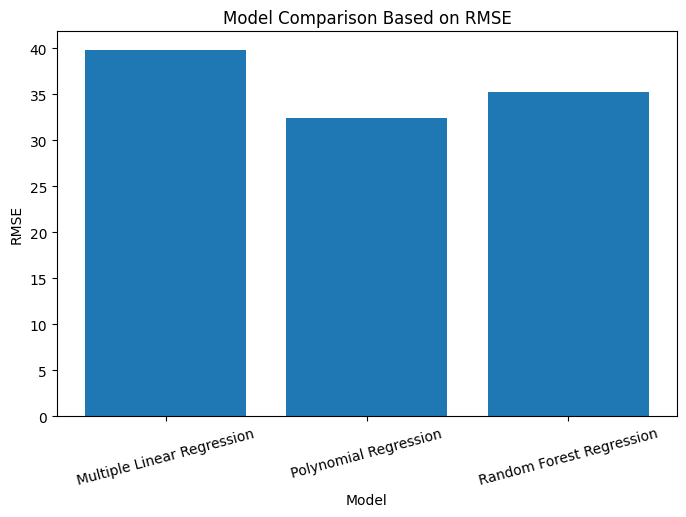

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison['Model'],
    comparison['RMSE']
)

plt.xlabel('Model')
plt.ylabel('RMSE')
plt.title('Model Comparison Based on RMSE')

plt.xticks(rotation=15)
plt.show()

**R² Comparision**

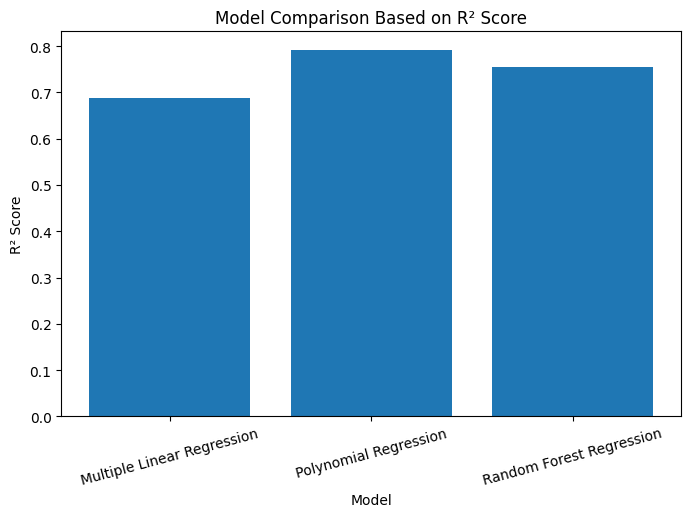

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    comparison['Model'],
    comparison['R2']
)

plt.xlabel('Model')
plt.ylabel('R² Score')
plt.title('Model Comparison Based on R² Score')

plt.xticks(rotation=15)
plt.show()

**Discount vs Predicted Sales**

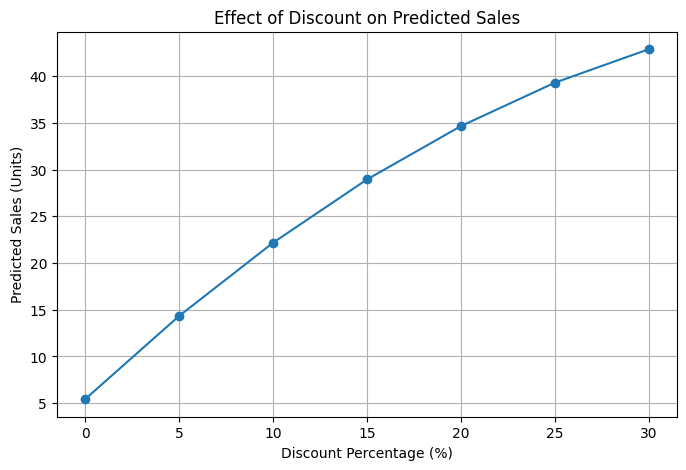

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    simulation_df['Discount_Percentage'],
    simulation_df['Predicted_Sales'],
    marker='o'
)

plt.xlabel('Discount Percentage (%)')
plt.ylabel('Predicted Sales (Units)')
plt.title('Effect of Discount on Predicted Sales')

plt.grid(True)
plt.show()

**Discount vs Expected Revenue**

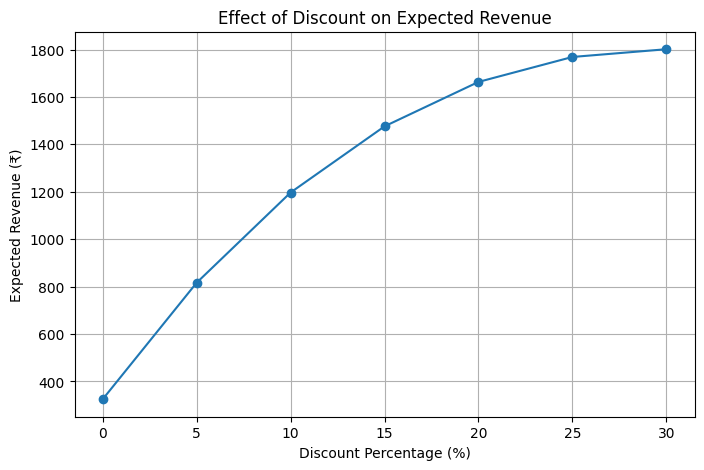

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    simulation_df['Discount_Percentage'],
    simulation_df['Expected_Revenue'],
    marker='o'
)

plt.xlabel('Discount Percentage (%)')
plt.ylabel('Expected Revenue (₹)')
plt.title('Effect of Discount on Expected Revenue')

plt.grid(True)
plt.show()

**Discount vs Unsold Stock**

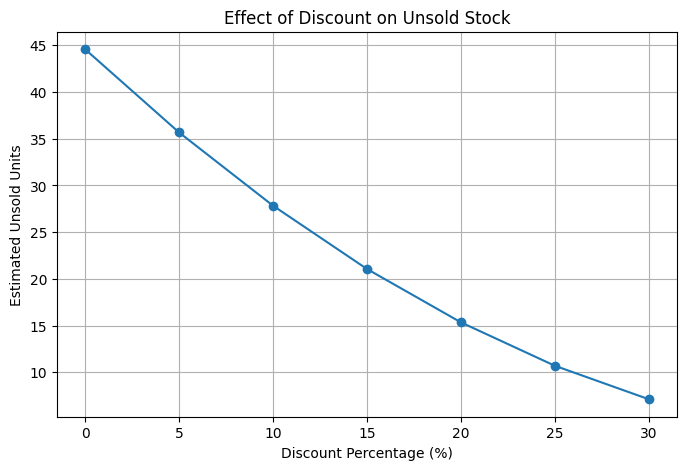

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    simulation_df['Discount_Percentage'],
    simulation_df['Estimated_Unsold'],
    marker='o'
)

plt.xlabel('Discount Percentage (%)')
plt.ylabel('Estimated Unsold Units')
plt.title('Effect of Discount on Unsold Stock')

plt.grid(True)
plt.show()

##Conclusion

In this project, we built a machine learning framework designed to solve a very practical problem for retailers: how to price items approaching their expiration date to minimize waste without sacrificing profit. By analyzing variables like current price, discount depth, remaining shelf life, past sales trends, stock levels, and seasonal patterns, we trained regression models to forecast product demand under different pricing scenarios.

We benchmarked three algorithms—Multiple Linear Regression, Polynomial Regression, and Random Forest Regression. Polynomial Regression emerged as the most reliable predictor, achieving the highest overall accuracy with an $R^2$ of **0.79** and an RMSE of **32.44**.

When applied to our test scenario, the model proved its worth by simulating various markdown levels to balance sales volume, total revenue, and leftover stock. For our sample product, it pinpointed a **30% discount** as the optimal sweet spot—projected to move **42.89 units**, capture **₹1,801.42 in revenue**, and leave roughly **7.11 units unsold**. Ultimately, this demonstrates how predictive demand modeling can help supermarkets and stores ditch arbitrary markdowns in favor of smart, automated pricing that protects margins and curbs food waste.

### Future Scope

* **Testing with Real-World Data:** Validate and fine-tune the algorithms using live transactional feeds from active retail stores rather than simulated datasets.
* **Broader Market Inputs:** Incorporate external dynamic signals into the model, such as real-time competitor pricing, local customer purchasing habits, and macro demand shifts.
* **Live Retailer Dashboard:** Build an interactive, user-friendly control panel where store managers can view automated discount recommendations and track inventory risks in real time.
* **Automated Discount Optimization:** Move beyond manual scenario testing by integrating mathematical optimization routines (e.g., dynamic programming or genetic algorithms) to instantly pinpoint the exact profit-maximizing discount.
* **Multi-Store Scaling:** Expand the model architecture to handle complex inventory networks across multiple product categories, store locations, and regional supply chains simultaneously.